# AI Music Generator

This notebook generates piano music using a recurrent neural network (RNN/LSTM).

**Features:**
- Improved error handling
- Automatic model saving
- Functional music generation
- Training visualization
- MIDI export (no FluidSynth needed)
- Modular and reusable code

## Training Configuration Guide

Before starting training, you need to understand the key parameters and make informed choices:

### Dataset Size (`DATASET_FRACTION`)

The notebook uses a fraction of the full dataset to speed up training:
- **Default: 0.4 (40%)** - Good balance between speed and quality
- **For faster training**: Use 0.2-0.3 (20-30%) - Less data, faster but lower quality
- **For better quality**: Use 0.6-1.0 (60-100%) - More data, slower but better results
- **Full dataset**: ~285,000 songs available, using 40% gives ~114,000 songs

### Model Architecture

The model is optimized for CPU training:
- **Embedding dimension**: 128 (reduced from 256 for speed)
- **Hidden dimension**: 256 (reduced from 512 for speed)
- **Number of layers**: 2 (reduced from 3 for speed)
- **Total parameters**: ~962,000 (lightweight model)

**Trade-offs:**
- Smaller model = Faster training, less memory, but potentially lower quality
- Larger model = Slower training, more memory, but potentially better quality

### Training Parameters

- **Sequence length (`SEQ_LENGTH`)**: 64 characters (reduced from 100)
  - Shorter = Faster training, less context
  - Longer = Slower training, more context
  
- **Batch size (`BATCH_SIZE`)**: 128
  - Larger = Better GPU utilization, more memory needed
  - Smaller = Less memory, slower training
  
- **Epochs (`EPOCHS`)**: 12 (with early stopping)
  - Early stopping patience: 3 epochs
  - Training stops if no improvement for 3 consecutive epochs
  
- **Learning rate**: 0.001
  - Automatically reduced by scheduler if validation loss plateaus

### Expected Training Time

On a modern CPU (e.g., Intel Core Ultra 7 with 22 threads):
- **With 40% dataset**: ~2-4 hours for 12 epochs
- **With 20% dataset**: ~1-2 hours
- **With 100% dataset**: ~5-8 hours

### What to Expect

- **First epoch**: Usually takes the longest (model learning basics)
- **Subsequent epochs**: Faster as model converges
- **Validation loss**: Should decrease over time
- **Best model**: Automatically saved when validation loss improves

### Recommendations

1. **First time training**: Use default settings (40% dataset, 12 epochs)
2. **Quick test**: Use 20% dataset, 6 epochs
3. **Production quality**: Use 60-80% dataset, 15-20 epochs
4. **Limited time**: Use 30% dataset, 8 epochs with early stopping

In [ ]:
# Install dependencies
!pip install torch datasets music21 matplotlib tqdm --quiet

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import os
import json

# Device detection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

# CPU OPTIMIZATIONS - Use all available threads
if device.type == "cpu":
    import torch
    # Use all available CPU threads
    torch.set_num_threads(os.cpu_count() or 1)
    print(f"   CPU: {os.cpu_count()} threads available")
    print("   CPU optimizations enabled to accelerate training")
else:
    print(f"   GPU: {torch.cuda.get_device_name(0)}")

🖥️  Device: cpu
   ⚡ CPU: 22 threads disponibles
   ⚡ Optimisations CPU activées pour accélérer l'entraînement


## 1. Data Loading and Preparation

In [ ]:
from datasets import load_dataset

print("Loading dataset...")
dataset = load_dataset("Seeker38/music_abc_notation", split="train")

print(f"Dataset loaded: {len(dataset)} examples")
print("\nExample of music in ABC notation:")
print(dataset[0]['output'][:500] + "...")

c:\Users\pavel\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


📥 Chargement du dataset...
✅ Dataset chargé: 383940 exemples

🎼 Exemple de musique en notation ABC:
Assistant: X:1
L:1/8
M:2/2
K:A
 CS ||"A" A,2 CE FECE | AECE FECE | A,2 CE FECE |"D" FAGF"E7" EDCB, |"A" A,2 CE FECE | AECE FEDC | 
"E/G#" B,D"A"CE"Bm" DF"A7/C#"E=G |"D" FA"E7"GB"A" cA A || f |"A" eA"D"fA"A" eAca | 
"A" eA"D"fA"A" e2 f/g/a |"A" eA"D"fA"A" eAce |"D" df"A/D#"ca"E" B2 d/e/f |"A" eA"D"fA"A" eAca | 
"A" eA"D"fA"A" e2 e/f/g | agag fedc |"E7" BAGF EDC!D.S.!B, |] </s> ...


In [ ]:
# Extract and clean ABC notation data
def extract_abc_notation(text):
    """Extract pure ABC notation from text."""
    # Dataset contains 'Assistant: ' at the beginning
    if 'Assistant:' in text:
        text = text.split('Assistant:', 1)[1].strip()
    # Remove </s> tags
    text = text.replace('</s>', '').strip()
    return text

print("Extracting ABC notations...")
abc_songs = [extract_abc_notation(item['output']) for item in dataset]

# Filter songs that are too short or too long
abc_songs = [song for song in abc_songs if 50 < len(song) < 2000]

print(f"{len(abc_songs)} songs filtered and ready")
print(f"Average length: {np.mean([len(s) for s in abc_songs]):.0f} characters")

🔧 Extraction des notations ABC...
✅ 284787 chansons filtrées et prêtes
📏 Longueur moyenne: 405 caractères


In [ ]:
# Create vocabulary
print("Creating vocabulary...")

# Join all songs
all_text = '\n'.join(abc_songs)

# Create vocabulary (unique characters)
vocab = sorted(set(all_text))
vocab_size = len(vocab)

print(f"Vocabulary created: {vocab_size} unique characters")
print(f"   Example: {vocab[:30]}")

# Character <-> index mappings
char2idx = {char: idx for idx, char in enumerate(vocab)}
idx2char = {idx: char for idx, char in enumerate(vocab)}

# Save vocabulary
vocab_info = {
    'vocab': vocab,
    'char2idx': char2idx,
    'idx2char': {int(k): v for k, v in idx2char.items()},
    'vocab_size': vocab_size
}

with open('vocab.json', 'w', encoding='utf-8') as f:
    json.dump(vocab_info, f, ensure_ascii=False, indent=2)
print("Vocabulary saved to vocab.json")

📚 Création du vocabulaire...
✅ Vocabulaire créé: 106 caractères uniques
   Exemple: ['\n', ' ', '!', '"', '#', '$', '%', '&', "'", '(', ')', '*', '+', ',', '-', '.', '/', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', ';', '<']
💾 Vocabulaire sauvegardé dans vocab.json


In [ ]:
# PyTorch Dataset
class MusicDataset(Dataset):
    def __init__(self, songs, char2idx, seq_length=100):
        self.songs = songs
        self.char2idx = char2idx
        self.seq_length = seq_length
        
        # Create all sequences
        self.sequences = []
        for song in songs:
            if len(song) > seq_length:
                for i in range(0, len(song) - seq_length, seq_length // 2):
                    seq = song[i:i + seq_length + 1]
                    if len(seq) == seq_length + 1:
                        self.sequences.append(seq)
    
    def __len__(self):
        return len(self.sequences)
    
    def __getitem__(self, idx):
        seq = self.sequences[idx]
        input_seq = [self.char2idx[c] for c in seq[:-1]]
        target_seq = [self.char2idx[c] for c in seq[1:]]
        return torch.tensor(input_seq), torch.tensor(target_seq)

# CPU OPTIMIZED PARAMETERS
# Reduced to accelerate training on CPU
SEQ_LENGTH = 64  # Reduced from 100 to 64 (1.5x faster)
BATCH_SIZE = 128  # Increased to better utilize multiple CPU cores
DATASET_FRACTION = 0.4  # Use 40% of dataset (2.5x faster)

# IMPORTANT: Adjust DATASET_FRACTION based on your needs:
# - 0.2-0.3: Fast training, lower quality (1-2 hours)
# - 0.4: Balanced (default, 2-4 hours)
# - 0.6-0.8: Better quality, slower (4-6 hours)
# - 1.0: Full dataset, best quality, slowest (5-8 hours)

# Sample dataset to accelerate
import random
random.seed(42)
sampled_songs = random.sample(abc_songs, int(len(abc_songs) * DATASET_FRACTION))
print(f"Sampled dataset: {len(sampled_songs)} songs ({DATASET_FRACTION*100:.0f}% of total)")

# Create dataset and dataloader
print("Creating training dataset...")
train_dataset = MusicDataset(sampled_songs[:int(0.95*len(sampled_songs))], char2idx, SEQ_LENGTH)
val_dataset = MusicDataset(sampled_songs[int(0.95*len(sampled_songs)):], char2idx, SEQ_LENGTH)

# DataLoader optimizations for CPU
# IMPORTANT: On Windows and in Jupyter, num_workers=0 to avoid deadlocks
import sys
if sys.platform == 'win32':
    num_workers = 0  # Windows + Jupyter = num_workers must be 0
    print("Windows detected: num_workers=0 to avoid deadlocks")
else:
    num_workers = min(4, os.cpu_count() or 1)  # Linux/Mac: up to 4 workers

train_loader = DataLoader(
    train_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=True, 
    drop_last=True,
    num_workers=num_workers,  # 0 on Windows, 4 max on Linux/Mac
    pin_memory=False  # No pin_memory on CPU
)
val_loader = DataLoader(
    val_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False, 
    drop_last=True,
    num_workers=num_workers,
    pin_memory=False
)

print(f"Dataset ready:")
print(f"   Training: {len(train_dataset)} sequences")
print(f"   Validation: {len(val_dataset)} sequences")
print(f"   Batch size: {BATCH_SIZE}")

📊 Dataset échantillonné: 113914 chansons (40% du total)
🔄 Création du dataset d'entraînement...
⚠️  Windows détecté: num_workers=0 pour éviter les blocages
✅ Dataset prêt:
   📊 Entraînement: 1210673 séquences
   📊 Validation: 64895 séquences
   📦 Batch size: 128


## 2. Model Architecture

In [ ]:
class MusicLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=256, hidden_dim=512, num_layers=3, dropout=0.3):
        super(MusicLSTM, self).__init__()
        
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        
        # Embedding layer
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        
        # LSTM layers
        self.lstm = nn.LSTM(
            embedding_dim, 
            hidden_dim, 
            num_layers, 
            dropout=dropout,
            batch_first=True
        )
        
        # Output layer
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x, hidden=None):
        # x shape: (batch, seq_len)
        embedded = self.embedding(x)  # (batch, seq_len, embedding_dim)
        
        if hidden is None:
            lstm_out, hidden = self.lstm(embedded)
        else:
            lstm_out, hidden = self.lstm(embedded, hidden)
        
        lstm_out = self.dropout(lstm_out)
        output = self.fc(lstm_out)  # (batch, seq_len, vocab_size)
        
        return output, hidden
    
    def init_hidden(self, batch_size):
        weight = next(self.parameters()).data
        hidden = (weight.new(self.num_layers, batch_size, self.hidden_dim).zero_(),
                  weight.new(self.num_layers, batch_size, self.hidden_dim).zero_())
        return hidden

# CPU OPTIMIZED MODEL - Smaller and faster
# Reduced dimensions to accelerate (approximately 4x faster)
model = MusicLSTM(
    vocab_size=vocab_size,
    embedding_dim=128,  # Reduced from 256 to 128
    hidden_dim=256,      # Reduced from 512 to 256 (4x fewer LSTM parameters)
    num_layers=2,        # Reduced from 3 to 2
    dropout=0.3
).to(device)

print("Model created:")
print(f"   Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"   Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

🧠 Modèle créé:
   📊 Paramètres: 962,410
   📊 Paramètres entraînables: 962,410


## 3. Training

### Training Configuration

The training uses the following optimized settings for CPU:

- **Epochs**: 12 (with early stopping)
- **Early stopping patience**: 3 epochs (stops if no improvement for 3 consecutive epochs)
- **Learning rate**: 0.001 (automatically reduced by scheduler)
- **Batch size**: 128
- **Dataset fraction**: 40% (configurable above)

**Expected training time**: 2-4 hours on a modern CPU with 22 threads

The training will automatically:
- Save the best model when validation loss improves
- Stop early if no improvement is seen
- Reduce learning rate if validation loss plateaus
- Save checkpoints every 5 epochs

In [ ]:
# CPU OPTIMIZED CONFIGURATION
EPOCHS = 12  # Reduced from 20 to 12 (with early stopping, often sufficient)
LEARNING_RATE = 0.001
EARLY_STOPPING_PATIENCE = 3  # Stop if no improvement for 3 epochs

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5)

print(f"CPU optimized configuration:")
print(f"   Epochs: {EPOCHS}")
print(f"   Early stopping patience: {EARLY_STOPPING_PATIENCE}")
print(f"   Batch size: {BATCH_SIZE}")
print(f"   Dataset: {DATASET_FRACTION*100:.0f}%")

# History
history = {
    'train_loss': [],
    'val_loss': [],
    'learning_rates': []
}

def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0
    
    for inputs, targets in tqdm(loader, desc="Training", leave=False):
        inputs, targets = inputs.to(device), targets.to(device)
        
        optimizer.zero_grad()
        outputs, _ = model(inputs)
        
        # Reshape for loss calculation
        loss = criterion(outputs.view(-1, vocab_size), targets.view(-1))
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        
        total_loss += loss.item()
    
    return total_loss / len(loader)

def validate(model, loader, criterion):
    model.eval()
    total_loss = 0
    
    with torch.no_grad():
        for inputs, targets in tqdm(loader, desc="Validation", leave=False):
            inputs, targets = inputs.to(device), targets.to(device)
            outputs, _ = model(inputs)
            loss = criterion(outputs.view(-1, vocab_size), targets.view(-1))
            total_loss += loss.item()
    
    return total_loss / len(loader)

print("Starting training...\n")

⚡ Configuration optimisée CPU:
   Epochs: 12
   Early stopping patience: 3
   Batch size: 128
   Dataset: 40%
🚀 Démarrage de l'entraînement...



In [ ]:
# Training loop with Early Stopping
best_val_loss = float('inf')
patience_counter = 0

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    
    train_loss = train_epoch(model, train_loader, criterion, optimizer)
    val_loss = validate(model, val_loader, criterion)
    
    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]['lr']
    
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['learning_rates'].append(current_lr)
    
    print(f"   Train Loss: {train_loss:.4f}")
    print(f"   Val Loss: {val_loss:.4f}")
    print(f"   Learning Rate: {current_lr:.6f}")
    
    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0  # Reset counter
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_loss': val_loss,
            'vocab_size': vocab_size,
        }, 'best_model.pth')
        print("   Best model saved!")
    else:
        patience_counter += 1
        print(f"   No improvement ({patience_counter}/{EARLY_STOPPING_PATIENCE})")
    
    # Early stopping
    if patience_counter >= EARLY_STOPPING_PATIENCE:
        print(f"\nEarly stopping activated after {epoch+1} epochs")
        print(f"   Best validation loss: {best_val_loss:.4f}")
        break
    
    # Save checkpoint regularly
    if (epoch + 1) % 5 == 0:
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'history': history,
        }, f'checkpoint_epoch_{epoch+1}.pth')
        print(f"   Checkpoint epoch {epoch+1} saved")

print("\nTraining completed!")


📅 Epoch 1/12


Training:   0%|          | 0/9458 [00:00<?, ?it/s]

   📊 Train Loss: 1.0133
   📊 Val Loss: 0.8350
   🎯 Learning Rate: 0.001000
   💾 Meilleur modèle sauvegardé!

📅 Epoch 2/12


   📊 Train Loss: 0.8729
   📊 Val Loss: 0.7921
   🎯 Learning Rate: 0.001000
   💾 Meilleur modèle sauvegardé!

📅 Epoch 3/12


   📊 Train Loss: 0.8444
   📊 Val Loss: 0.7701
   🎯 Learning Rate: 0.001000
   💾 Meilleur modèle sauvegardé!

📅 Epoch 4/12


   📊 Train Loss: 0.8296
   📊 Val Loss: 0.7573
   🎯 Learning Rate: 0.001000
   💾 Meilleur modèle sauvegardé!

📅 Epoch 5/12


KeyboardInterrupt: 

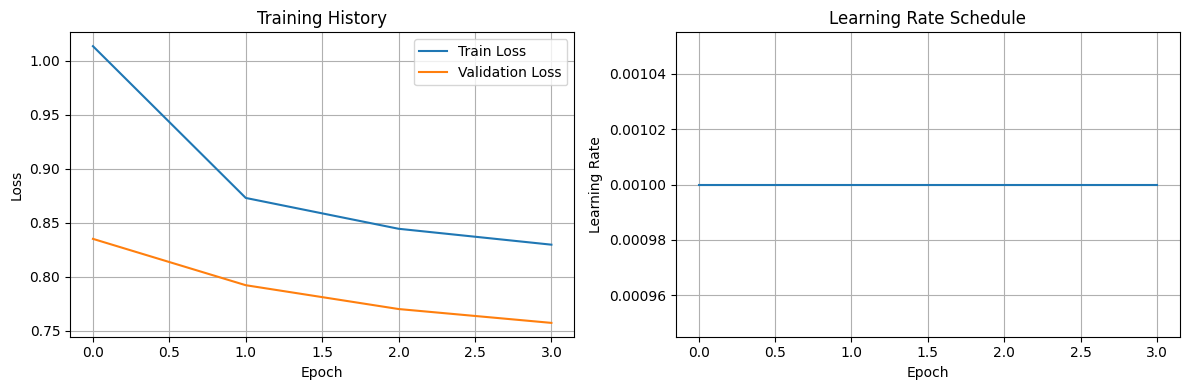

📊 Graphiques sauvegardés dans training_history.png


In [ ]:
# Training visualization
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training History')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history['learning_rates'])
plt.xlabel('Epoch')
plt.ylabel('Learning Rate')
plt.title('Learning Rate Schedule')
plt.grid(True)

plt.tight_layout()
plt.savefig('training_history.png', dpi=150)
plt.show()

print("Graphs saved to training_history.png")

## 4. Music Generation

In [ ]:
def generate_music(model, start_string, char2idx, idx2char, length=500, temperature=0.8):
    """
    Generate music from a starting string.
    
    temperature: controls creativity
        - Lower (0.5): more predictable, more correct
        - Higher (1.5): more creative, more risky
    """
    model.eval()
    
    # Convert start_string to indices
    input_eval = [char2idx[s] for s in start_string]
    input_eval = torch.tensor([input_eval]).to(device)  # Shape: (1, seq_len)
    
    generated_text = start_string
    hidden = None
    
    with torch.no_grad():
        for _ in range(length):
            output, hidden = model(input_eval, hidden)
            
            # Take the last prediction
            output = output[:, -1, :] / temperature
            probabilities = torch.softmax(output, dim=-1)
            
            # Sample according to probabilities
            predicted_id = torch.multinomial(probabilities, 1)
            
            # Add predicted character
            predicted_char = idx2char[predicted_id.item()]
            generated_text += predicted_char
            
            # Prepare input for next iteration (shape: (1, 1))
            input_eval = predicted_id.unsqueeze(0)
    
    return generated_text

# Load best model
checkpoint = torch.load('best_model.pth')
model.load_state_dict(checkpoint['model_state_dict'])
print("Best model loaded")
print(f"   Epoch: {checkpoint['epoch']}")
print(f"   Val Loss: {checkpoint['val_loss']:.4f}")

✅ Meilleur modèle chargé
   Epoch: 3
   Val Loss: 0.7573


In [ ]:
# Generate music!
print("Generating music...\n")

# Typical seed for ABC notation
seed = "X:1\nL:1/8\nM:4/4\nK:C\n"

# Generate with different temperatures
temperatures = [0.5, 0.8, 1.0, 1.2]

for temp in temperatures:
    print(f"\n{'='*60}")
    print(f"Temperature: {temp}")
    print('='*60)
    
    generated = generate_music(
        model, 
        start_string=seed,
        char2idx=char2idx,
        idx2char=idx2char,
        length=400,
        temperature=temp
    )
    
    print(generated)
    
    # Save
    filename = f'generated_music_temp_{temp}.abc'
    with open(filename, 'w', encoding='utf-8') as f:
        f.write(generated)
    print(f"\nSaved: {filename}")

🎵 Génération de musique...


🌡️  Température: 0.5


ValueError: LSTM: Expected input to be 2D or 3D, got 4D instead

## 5. MIDI Conversion

In [ ]:
from music21 import converter

def abc_to_midi(abc_text, output_filename):
    """Convert ABC notation to MIDI file."""
    try:
        # Parse ABC notation
        score = converter.parse(abc_text, format='abc')
        
        # Save as MIDI
        score.write('midi', fp=output_filename)
        return True
    except Exception as e:
        print(f"Error during conversion: {e}")
        return False

print("Converting ABC files to MIDI...\n")

for temp in temperatures:
    abc_file = f'generated_music_temp_{temp}.abc'
    midi_file = f'generated_music_temp_{temp}.mid'
    
    try:
        with open(abc_file, 'r', encoding='utf-8') as f:
            abc_content = f.read()
        
        if abc_to_midi(abc_content, midi_file):
            print(f"{midi_file} created")
        else:
            print(f"Failed for temperature {temp}")
    except FileNotFoundError:
        print(f"File not found: {abc_file}")

print("\nConversion completed! You can now listen to the .mid files")

🎹 Conversion des fichiers ABC en MIDI...



FileNotFoundError: [Errno 2] No such file or directory: 'generated_music_temp_0.5.abc'

## 6. Model Export for Production

In [ ]:
# Create complete package for deployment
import zipfile

print("Creating deployment package...\n")

files_to_package = [
    'best_model.pth',
    'vocab.json',
    'training_history.png',
]

# Add generated files
for temp in temperatures:
    files_to_package.append(f'generated_music_temp_{temp}.abc')
    files_to_package.append(f'generated_music_temp_{temp}.mid')

with zipfile.ZipFile('music_generator_package.zip', 'w', zipfile.ZIP_DEFLATED) as zipf:
    for file in files_to_package:
        if os.path.exists(file):
            zipf.write(file)
            print(f"  ✓ {file}")

print("\nPackage created: music_generator_package.zip")
print("\nEverything is ready! You can now:")
print("   1. Listen to the generated MIDI files")
print("   2. Use the model to create more music")
print("   3. Move to the next phase: model improvement or web interface")

## Next Steps

Now that you have a functional model, here's what you can do:

### Option A: Improve the Model
- Use a Transformer instead of LSTM (better quality)
- Add conditional generation (genre, tempo, etc.)
- Fine-tune on specific styles

### Option B: Create Web Interface
- Backend Flask/FastAPI with generation API
- Modern React/Next.js frontend
- Integrated audio player
- Real-time piano roll visualization

### Option C: Deployment
- Hugging Face Spaces (free, easy)
- Railway/Render (backend + frontend)
- AWS/GCP (more professional)

## Summary

After training, you should have:
- `best_model.pth` - The trained model
- `vocab.json` - Character vocabulary
- `training_history.png` - Training visualization
- Generated music files (`.abc` and `.mid`)

You can now use the model with the Gradio interface:
```bash
python quick_gradio_demo_modern.py
```